## MeshLab Tutorial

Generate a mesh to export.

### 1. Import packages
---

In [1]:
import numpy as np

from copy import deepcopy

from meshlab.data import Mesh, Contour
from meshlab.operations import insert_contour, compute_normals, advance_front, smooth_normals
from meshlab.visualization import plot_mesh
from meshlab.export import export_mesh

### 2. Define parameters
---

In [2]:
num_layers = 10               # Number of layers
height = 0.005                # First layer height
growth_rate = 1.10            # Ratio between two consecutive layers
smooth_steps = 5              # Number of smoothing steps
relaxation = 1.0              # Relaxation factor
radius = 10.0                 # Farfield radius
filename = "NACA-2412.msh"    # Output filename

### 3. Geometry definition
---

In [3]:
# Upload NACA 2412 airfoil
points = np.loadtxt("./data/NACA-2412.dat")

### 4. Create boudary layer mesh
---

Initialize mesh, surface and front

In [4]:
# Initialize mesh and surfaces
mesh = Mesh( vertices_capacity=5000, cells_capacity=5000)
surface = Contour(name="wall", capacity=points.shape[0])

# Insert contour into mesh
insert_contour(mesh, surface, points)

# Create front based on surfaces
front = deepcopy(surface)
front.name = "Front"

Create the boundary layer

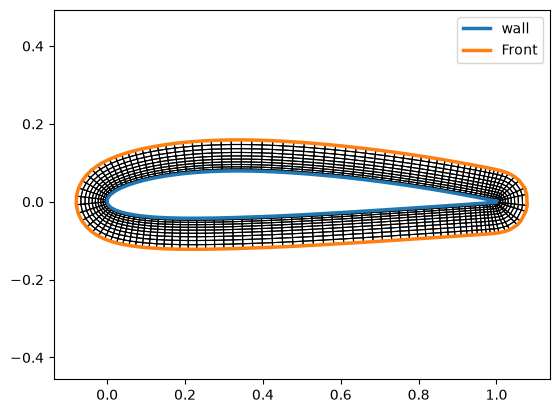

In [5]:
for layer in range(num_layers):
    normals = compute_normals(mesh, front, method="central")

    for _ in range(smooth_steps):
            normals, _ = smooth_normals(normals, relaxation)
    
    front = advance_front(mesh, front, normals, height)

    height *= growth_rate

# Visualize the mesh
plot_mesh(mesh, [surface, front])

Create farfield

In [6]:
# Define farfield points
alpha = np.linspace(0.0, 2.0 * np.pi, 80, endpoint=False)
points = np.column_stack([radius * np.cos(alpha), radius * np.sin(alpha)])

# Define farfield contour
farfield = Contour(name="freestream", capacity=points.shape[0])

# Insert contour in mesh
insert_contour(mesh, farfield, points)

Export gmsh file

In [7]:
export_mesh(
    mesh=mesh,
    walls=[surface],
    fronts=[front],
    farfield=farfield,
    filename="./results/" + filename,
)